# Project 1: Monte Carlo uncertainty for a gridded resource estimate

**Objective.** Show how parameter uncertainty propagates into a regional resource total, and how the answer depends on whether cell-level errors are independent or spatially shared.

**Problem.** A regional estimate is a sum over grid cells. Each input (rock thickness, porosity, temperature contrast) is uncertain, and the inputs are correlated with each other. A single deterministic total hides that uncertainty, so this notebook reports P90, P50 and P10 values instead.

**Data.** All inputs are **synthetic**. `src/geothermal_mc/synthetic.py` generates smooth mean and standard-deviation surfaces with a fixed seed. They are not geothermal observations and must not be read as a resource assessment. The energy formula is an illustrative proxy, and its heat-capacity constant is an assumption.

**Scope.** Correlated sampling with a Cholesky factor, two spatial error models, percentile reporting, a convergence check and a rank-based sensitivity check. This is a demonstration of method, not validation.

## 1. Imports and configuration

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

sys.path.insert(0, str(Path("../src").resolve()))
from geothermal_mc import assert_aligned, run_monte_carlo, summarise_totals
from geothermal_mc.sampling import parameter_sensitivity, resource_pj
from geothermal_mc.synthetic import CELL_SIZE_M, CRS, PARAMETERS, write_input_rasters

SEED = 42
N_DRAWS = 4000
DATA_DIR = Path("../data")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

# Correlation between (thickness_m, porosity, delta_t_k) within a cell.
# Thickness and temperature contrast are assumed positively correlated.
CORR = np.array([
    [1.0, 0.0, 0.5],
    [0.0, 1.0, 0.0],
    [0.5, 0.0, 1.0],
])
print("Correlation matrix (assumed):")
print(pd.DataFrame(CORR, index=PARAMETERS, columns=PARAMETERS))

Correlation matrix (assumed):
             thickness_m  porosity  delta_t_k
thickness_m          1.0       0.0        0.5
porosity             0.0       1.0        0.0
delta_t_k            0.5       0.0        1.0


## 2. Generate and check the input rasters
The synthetic surfaces are written as GeoTIFFs and checked for a shared grid before any use.

In [2]:
paths = write_input_rasters(DATA_DIR, seed=SEED)
assert_aligned([str(p) for p in paths.values()])
print("All six input rasters share CRS, transform and shape.")

rows = []
for name, path in paths.items():
    with rasterio.open(path) as src:
        arr = src.read(1)
        rows.append({
            "layer": name,
            "crs": src.crs.to_string(),
            "shape": f"{src.height} x {src.width}",
            "cell_m": src.res[0],
            "min": float(np.nanmin(arr)),
            "max": float(np.nanmax(arr)),
            "nan_cells": int(np.isnan(arr).sum()),
        })
qa = pd.DataFrame(rows)
qa

All six input rasters share CRS, transform and shape.


,layer,crs,shape,cell_m,min,max,nan_cells
0,thickness_m_mean,EPSG:32633,25 x 25,500.0,770.900635,1418.845459,0
1,thickness_m_sd,EPSG:32633,25 x 25,500.0,77.090065,141.884552,0
2,porosity_mean,EPSG:32633,25 x 25,500.0,0.020000,0.130361,0
3,porosity_sd,EPSG:32633,25 x 25,500.0,0.010000,0.010000,0
4,delta_t_k_mean,EPSG:32633,25 x 25,500.0,112.744827,154.525330,0
5,delta_t_k_sd,EPSG:32633,25 x 25,500.0,9.019586,12.362027,0


**Quality checks.** The grids share a CRS (UTM 33N, metres), a 500 m cell size and a shape. Every value is finite, and the porosity values stay inside (0, 1). The standard deviations are small relative to the means, which matches the assumed uncertainty levels.

## 3. Exploratory view of the inputs

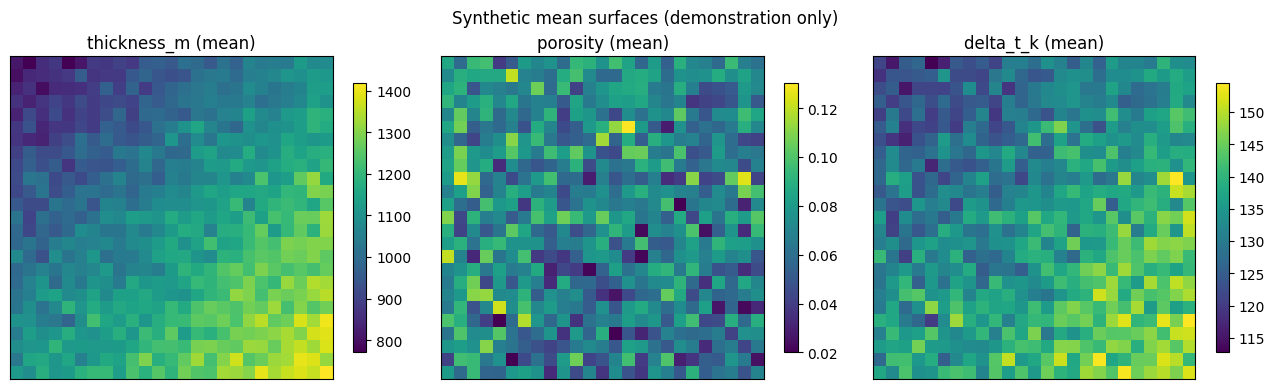

In [3]:
def read_layer(name):
    with rasterio.open(paths[name]) as src:
        return src.read(1)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, name in zip(axes, ["thickness_m_mean", "porosity_mean", "delta_t_k_mean"]):
    im = ax.imshow(read_layer(name), cmap="viridis")
    ax.set_title(name.replace("_mean", " (mean)"))
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle("Synthetic mean surfaces (demonstration only)")
fig.tight_layout()
fig.savefig(FIG_DIR / "input_means.png", dpi=120)
plt.show()

## 4. Build the per-cell parameter arrays and the deterministic baseline

In [4]:
names = ["thickness_m", "porosity", "delta_t_k"]
means = np.column_stack([read_layer(f"{n}_mean").ravel() for n in names])
sds = np.column_stack([read_layer(f"{n}_sd").ravel() for n in names])
cell_area = CELL_SIZE_M ** 2

deterministic_pj = resource_pj(means[:, 0], means[:, 1], means[:, 2], cell_area).sum()
print(f"Cells: {means.shape[0]}, cell area: {cell_area:.0f} m^2")
print(f"Deterministic regional total (means only): {deterministic_pj:,.0f} PJ")

Cells: 625, cell area: 250000 m^2
Deterministic regional total (means only): 4,082 PJ


## 5. Monte Carlo under two spatial error models

- **independent**: each cell receives its own error draw. Errors partly cancel when cells are summed.
- **shared**: one error draw applies to every cell. This is the fully correlated case and gives the widest total.

Both use the same correlation between parameters within a cell.

In [5]:
results = {
    mode: run_monte_carlo(means, sds, CORR, cell_area, N_DRAWS, SEED, spatial=mode)
    for mode in ["independent", "shared"]
}
summary = pd.DataFrame({m: summarise_totals(r.totals_pj) for m, r in results.items()}).T
summary = summary[["P90", "P50", "P10", "mean"]].round(0)
summary

,P90,P50,P10,mean
independent,4053.0,4100.0,4145.0,4099.0
shared,2999.0,4040.0,5262.0,4089.0


## 6. Convergence check
The P50 should be stable as the number of draws grows. This checks whether `N_DRAWS` is large enough.

In [6]:
conv = []
for n in [250, 500, 1000, 2000, 4000]:
    r = run_monte_carlo(means, sds, CORR, cell_area, n, SEED, spatial="independent", keep_samples=False)
    s = summarise_totals(r.totals_pj)
    conv.append({"draws": n, "P90": s["P90"], "P50": s["P50"], "P10": s["P10"]})
conv = pd.DataFrame(conv).round(0)
conv["P50_change_pct"] = (conv["P50"].pct_change() * 100).round(2)
conv

,draws,P90,P50,P10,P50_change_pct
0,250,4053.0,4096.0,4144.0,NaN
1,500,4055.0,4098.0,4144.0,0.05
2,1000,4056.0,4100.0,4146.0,0.05
3,2000,4053.0,4100.0,4145.0,0.00
4,4000,4053.0,4100.0,4145.0,0.00


## 7. Sensitivity: which input drives the total?

In [7]:
sens = pd.DataFrame({m: parameter_sensitivity(r.samples, r.totals_pj) for m, r in results.items()}).round(3)
sens

,independent,shared
thickness_m,0.623,0.639
porosity,0.615,0.659
delta_t_k,0.576,0.603


## 8. Results and visualisation

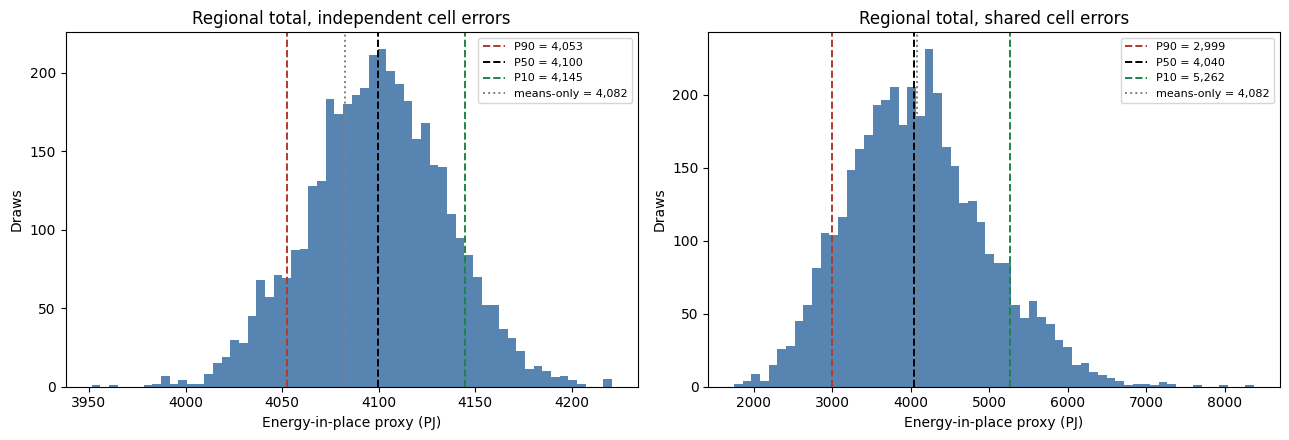

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, (mode, r) in zip(axes, results.items()):
    ax.hist(r.totals_pj, bins=60, color="#3b6ea5", alpha=0.85)
    s = summarise_totals(r.totals_pj)
    for key, color in [("P90", "#b03a2e"), ("P50", "black"), ("P10", "#1e8449")]:
        ax.axvline(s[key], color=color, ls="--", lw=1.4, label=f"{key} = {s[key]:,.0f}")
    ax.axvline(deterministic_pj, color="grey", ls=":", lw=1.4, label=f"means-only = {deterministic_pj:,.0f}")
    ax.set_title(f"Regional total, {mode} cell errors")
    ax.set_xlabel("Energy-in-place proxy (PJ)")
    ax.set_ylabel("Draws")
    ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIG_DIR / "total_distributions.png", dpi=120)
plt.show()

Sensitivity bar chart: Spearman rank correlation between each input's regional mean and the total.

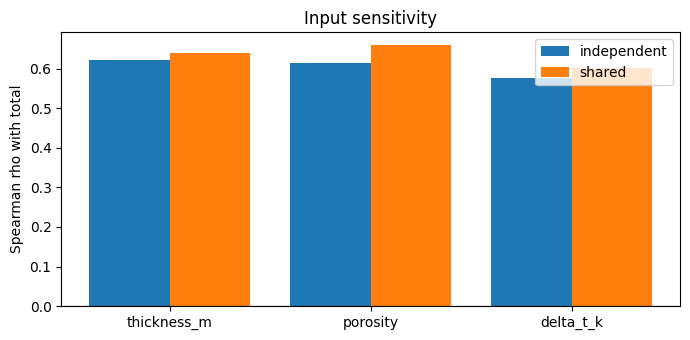

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(len(sens.index))
ax.bar(x - 0.2, sens["independent"], width=0.4, label="independent")
ax.bar(x + 0.2, sens["shared"], width=0.4, label="shared")
ax.set_xticks(x, sens.index)
ax.set_ylabel("Spearman rho with total")
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Input sensitivity")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "sensitivity.png", dpi=120)
plt.show()

## 9. Interpretation, limitations and next steps

**Result 1: the spatial error model matters more than the sample size.** With independent cell errors, the P90-to-P10 range is about 4,053 to 4,145 PJ, roughly ±1% around the P50 of 4,100 PJ. Averaging over 625 cells cancels most of the per-cell error. With shared errors, the same inputs give 2,999 to 5,262 PJ, roughly −26% to +30%. The estimate is almost identical in both cases (P50 4,040 to 4,100 PJ), so the difference is in the width of the range, not the centre. A reviewer should ask which error model a real estimate assumes before trusting a narrow interval.

**Result 2: the Monte Carlo mean sits close to the deterministic total.** The means-only total is 4,082 PJ and the sampled mean is 4,089 to 4,099 PJ. The small gap comes from the non-linear product in the energy formula and from clipping at physical bounds.

**Result 3: sampling is stable at this size.** P50 changes by less than 0.1% between 500 and 4,000 draws, so `N_DRAWS = 4000` is enough for this grid. This is a convergence check on the output, not a formal error bound.

**Result 4: all three inputs matter, with little to separate them.** The Spearman correlations between each input's regional mean and the total are about 0.58 to 0.66 in both modes. Porosity ranks highest, but the gaps are small. With 4,000 draws, the standard error of a Spearman coefficient is about 0.02, so the ordering should not be over-interpreted. The inputs were given similar relative uncertainties (about 8 to 12%), so this result depends on that choice.

**Limitations**

- All inputs are synthetic, and the energy formula is a proxy. The results show how the method behaves, not what any real site contains.
- The correlation matrix is assumed, not estimated from data. Its effect on the spread is part of what the notebook demonstrates, but its actual value would need evidence.
- Each cell's uncertainty is Gaussian and independent or fully shared. Real spatial uncertainty is usually partly correlated over a distance. Modelling that needs a variogram or a spatial covariance model.
- Porosity means were clipped at 0.02 in some cells (the minimum of the mean surface is exactly 0.02), so the sampled distribution is truncated there.
- The sensitivity measure is a rank correlation on regional means. It does not separate interaction effects, and a one-at-a-time or variance-based analysis would be a better next step.

**Next steps**

- Replace the two spatial extremes with a spatially correlated field (for example, an exponential covariance over cell distance).
- Add a one-at-a-time tornado analysis and compare it with the rank measure.
- Apply the same workflow to a real, licensed raster stack, checking the CRS and alignment with the existing `assert_aligned` check first.